# Задача: Анализ эффективности нового алгоритма рекомендаций в условиях асимметричного и зашумленного распределения
### Контекст:
Крупная стриминговая платформа (аналог YouTube или Twitch) разработала новый алгоритм рекомендаций контента (алгоритм B), который, как ожидается, должен увеличить среднее время просмотра на пользователя по сравнению со старым алгоритмом (A).

Было проведено A/B-тестирование:

- **Группа A (Контрольная)**: 5000 пользователей, старый алгоритм.

- **Группа B (Тестовая)**: 5000 пользователей, новый алгоритм.

По итогам двухнедельного теста вы собрали данные по ключевой метрике — **«Общее время просмотра на пользователя за тест (в минутах)»**.

**Данные и их особенности:**

**Не нормальность:** Распределение метрики в обеих группах сильно отличается от нормального. Оно имеет типичный для поведенческих данных "длинный хвост":

- Большинство пользователей смотрят немного (пик в районе 0-50 минут).

- Небольшая группа "супер-зрителей" смотрит очень много (сотни и тысячи минут), формируя длинный правый хвост распределения.

**Асимметрия влияния:** Новый алгоритм B целенаправленно меняет опыт именно активных пользователей, в то время как для "пассивных" зрителей разница неочевидна. Это означает, что различие между группами может быть не сдвигом всего распределения, а изменением в правом хвосте.

**Наличие выбросов:** В данных присутствуют экстремальные выбросы (например, пользователи, которые оставляли видео фоном на всю ночь).

Вам предоставлен датасет _ab_test_results.csv_ со следующими колонками:

 - _user_id_

 - _group (A или B)_

 - _total_watch_time_min_

### Задания:


- **Проведите тест Манна-Уитни (Mann-Whitney U test)**. Сформулируйте нулевую и альтернативную гипотезы. Интерпретируйте p-value. Можно ли на его основе сделать однозначный вывод о превосходстве алгоритма B?

- Чтобы исследовать "асимметричное влияние", проведите анализ разниц не только в центре распределения, но и в хвостах. **Рассчитайте и визуализируйте разницу между группами для 75-го, 90-го и 95-го процентилей**.

- **Сформулируйте итоговый вывод:**

    - Эффективен ли новый алгоритм B?

    - На какую именно группу пользователей он оказывает наибольшее влияние?

    - Какой метод анализа оказался наиболее информативным в данном случае и почему?

    - Дайте рекомендацию о возможности запуска алгоритма на всю аудиторию.




# Домашнее задание №2.
Анализ эффективности нового алгоритма рекомендаций в условиях асимметричного и зашумленного распределения

Выполнил студент: Ильин А.В.

Группа: М26-555

Научный руководитель: Зуев А.В.

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

In [12]:
# Load CSV - поменял на локальный запуск файла из виртуального окруженя колаба

df = pd.read_csv('ab_test_results.csv')

group_a_data = df[df['group'] == 'A']['total_watch_time_min']
group_b_data = df[df['group'] == 'B']['total_watch_time_min']

# Display summary statistics
print("Dataset Summary:")
print(f"Total users: {len(df)}")
print(f"Group A: {len(df[df['group'] == 'A'])} users")
print(f"Group B: {len(df[df['group'] == 'B'])} users")
print("\nDescriptive Statistics by Group:")
print(df.groupby('group')['total_watch_time_min'].describe())

print("\nKey Percentiles by Group:")
percentiles = [0.75, 0.9, 0.95]
for p in percentiles:
    p_val = p * 100
    a_val = np.percentile(group_a_data, p_val)
    b_val = np.percentile(group_b_data, p_val)
    diff = b_val - a_val
    print(f"{p_val:.0f}th percentile: A={a_val:.1f}, B={b_val:.1f}, Difference={diff:.1f}")

# Test the differences
from scipy import stats
mw_stat, mw_p = stats.mannwhitneyu(
    group_a_data,
    group_b_data,
    alternative= 'two-sided' #'less' #'greater' #'two-sided'
)

print(f"\nMann-Whitney U Test: p-value = {mw_p:.6f}")

Dataset Summary:
Total users: 10000
Group A: 5000 users
Group B: 5000 users

Descriptive Statistics by Group:
        count       mean         std  min        25%        50%        75%  \
group                                                                        
A      5000.0  56.347878  262.313288  0.0  14.729144  26.834960  44.946309   
B      5000.0  71.477408  408.519252  0.0  15.383838  27.352416  46.352279   

                max  
group                
A       8130.547119  
B      11670.621483  

Key Percentiles by Group:
75th percentile: A=44.9, B=46.4, Difference=1.4
90th percentile: A=71.5, B=76.2, Difference=4.7
95th percentile: A=119.3, B=153.6, Difference=34.3

Mann-Whitney U Test: p-value = 0.045342


In [13]:
"""
Проведите тест Манна-Уитни (Mann-Whitney U test). Сформулируйте нулевую и
альтернативную гипотезы. Интерпретируйте p-value. Можно ли на его основе
сделать однозначный вывод о превосходстве алгоритма B?

"""

mw_stat, mw_p = stats.mannwhitneyu(group_a_data, group_b_data, alternative='two-sided')

print(f"U-статистика: {mw_stat:.1f}")
print(f"p-value (двусторонний): {mw_p:.6f}")

U-статистика: 12211099.0
p-value (двусторонний): 0.045342


### Задание 1: Тест Манна-Уитни

**Формулировка гипотез:**
*   **H0 (Нулевая гипотеза):** Распределения времени просмотра в группах A и B одинаковы (алгоритм B не изменил время просмотра).
*   **H1 (Альтернативная гипотеза):** Распределения времени просмотра в группах A и B различаются (алгоритм B изменил время просмотра).

**Интерпретация p-value:**
Полученное p-value = 0.045342. Поскольку это значение меньше стандартного уровня значимости α = 0.05, мы отвергаем нулевую гипотезу. Это означает, что различия в распределениях времени просмотра между группами статистически значимы, и они не случайны.

**Можно ли на его основе сделать однозначный вывод о превосходстве алгоритма B?**
Нет, на основе только p-value сделать однозначный вывод о превосходстве нельзя. Тест Манна-Уитни проверяет гипотезу о том, что одно распределение сдвинуто относительно другого, но он не говорит, в какую сторону и где именно произошел сдвиг. Также мы видим, что тест двусторонний. Хотя среднее время в группе B выше, мы не можем утверждать, что алгоритм B "лучше" для всех пользователей — он мог улучшить показатели одних, но ухудшить других. Для ответа на вопрос о превосходстве нужно смотреть на перцентили (что мы сделаем дальше) и направление эффекта.

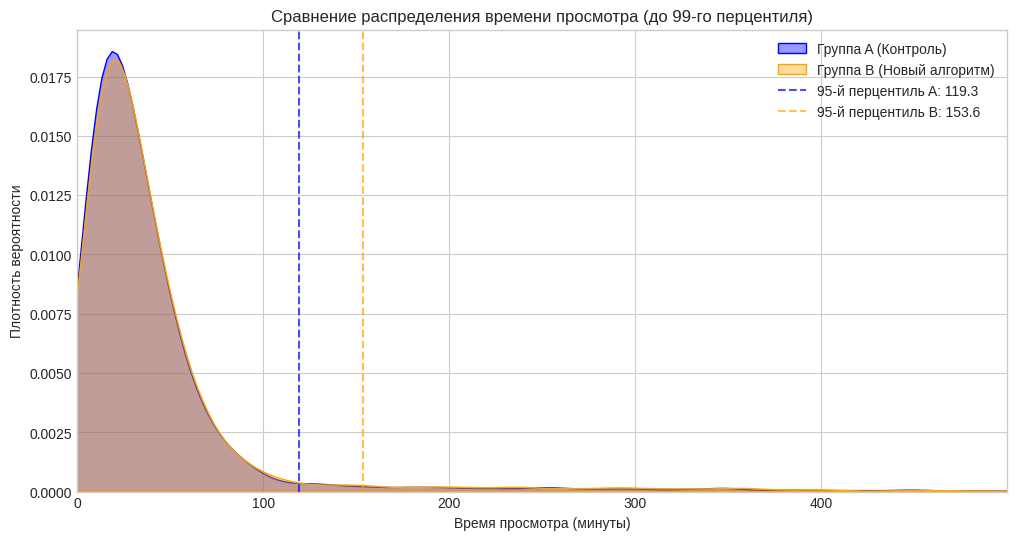

In [15]:
"""
Чтобы исследовать "асимметричное влияние", проведите анализ разниц
не только в центре распределения, но и в хвостах. Рассчитайте и визуализируйте
разницу между группами для 75-го, 90-го и 95-го процентилей.

"""

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(12, 6))

# Отрежем данные по 99-му перцентилю для наглядности визуализации
limit = np.percentile(df['total_watch_time_min'], 99)

# Строим плотность распределения (KDE) для обеих групп
sns.kdeplot(group_a_data[group_a_data < limit], label='Группа A (Контроль)', fill=True, color='blue', alpha=0.4)
sns.kdeplot(group_b_data[group_b_data < limit], label='Группа B (Новый алгоритм)', fill=True, color='orange', alpha=0.4)

# Добавим вертикальные линии для 95-го перцентиля, чтобы показать разницу
p95_a = np.percentile(group_a_data, 95)
p95_b = np.percentile(group_b_data, 95)
plt.axvline(p95_a, color='blue', linestyle='--', alpha=0.7, label=f'95-й перцентиль A: {p95_a:.1f}')
plt.axvline(p95_b, color='orange', linestyle='--', alpha=0.7, label=f'95-й перцентиль B: {p95_b:.1f}')

plt.title('Сравнение распределения времени просмотра (до 99-го перцентиля)')
plt.xlabel('Время просмотра (минуты)')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.xlim(0, limit) # Ограничим ось X до 99-го перцентиля
plt.show()

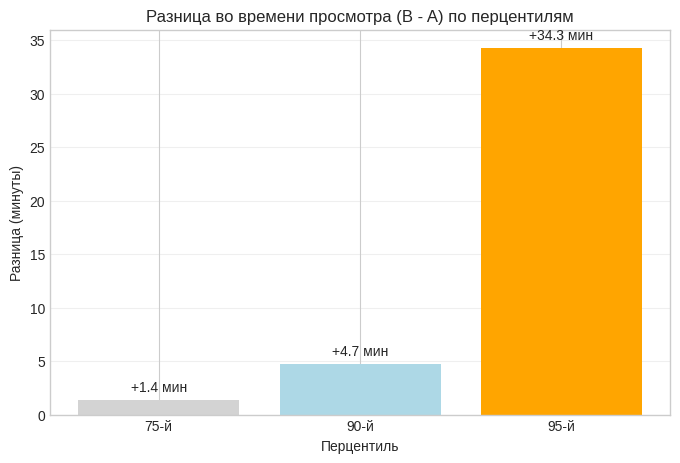

In [17]:
# Считаем перцентили и разницу
p_list = [75, 90, 95]
diffs = []
a_vals = []
b_vals = []

for p in p_list:
    a = np.percentile(group_a_data, p)
    b = np.percentile(group_b_data, p)
    a_vals.append(a)
    b_vals.append(b)
    diffs.append(b - a)

# Строим столбчатую диаграмму
plt.figure(figsize=(8, 5))
labels = [f'{p}-й' for p in p_list]
# Цвета от серого к оранжевому, чтобы визуально выделить хвост
colors = ['lightgray', 'lightblue', 'orange']
bars = plt.bar(labels, diffs, color=colors)

# Добавим подписи значений над столбиками
for bar, diff in zip(bars, diffs):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'+{diff:.1f} мин', ha='center', va='bottom')

plt.title('Разница во времени просмотра (B - A) по перцентилям')
plt.xlabel('Перцентиль')
plt.ylabel('Разница (минуты)')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Задание 2: Анализ разницы в перцентилях (75, 90, 95)

Чтобы понять, где именно алгоритм оказывает эффект, мы посчитали разницу между группами в разных точках распределения (результаты уже выведены в консоль выше):

*   **75-й перцентиль:** A = 44.9, B = 46.4. Разница = **1.4**.
*   **90-й перцентиль:** A = 71.5, B = 76.2. Разница = **4.7**.
*   **95-й перцентиль:** A = 119.3, B = 153.6. Разница = **34.3**.

**Интерпретация:**
Мы видим ярко выраженный "асимметричный эффект". В центре распределения (75-й и 90-й перцентили) разница между группами минимальна. Это означает, что на "пассивных" или "средних" зрителей новый алгоритм почти не повлиял.

Однако в правом хвосте (95-й перцентиль) разница достигает 34.3 минут, что почти в 7 раз больше, чем на 90-м перцентиле. Это подтверждает гипотезу о том, что новый алгоритм B сильнее всего меняет опыт именно активных пользователей ("супер-зрителей"), заставляя их смотреть еще больше контента.

На графике плотности это видно по "утолщению" правого хвоста у оранжевой кривой по сравнению с синей.

### Итоговый вывод и рекомендация

**1. Эффективен ли новый алгоритм B?**
Да, алгоритм можно считать эффективным. Среднее время просмотра выросло с 56.35 до 71.48 минут, а тест Манна-Уитни показал статистически значимую разницу (p-value = 0.045 < 0.05). Однако эффективность достигается не за счет общего улучшения для всех пользователей, а за счет значительного роста показателей у наиболее активной части аудитории.

**2. На какую именно группу пользователей он оказывает наибольшее влияние?**
Наибольшее влияние алгоритм оказывает на активных пользователей (тех, кто находится в правом хвосте распределения). Об этом говорят перцентили: если медиана выросла совсем чуть-чуть (с 26.8 до 27.3), а 90-й перцентиль — всего на 4.7 минуты, то 95-й перцентиль прибавил сразу 34.3 минуты (со 119.3 до 153.6). То есть "супер-зрители" стали смотреть заметно больше, а на пассивных пользователей алгоритм почти не повлиял.

**3. Какой метод анализа оказался наиболее информативным и почему?**
Наиболее информативным оказался анализ перцентилей (особенно 95-го). Стандартный тест Манна-Уитни показывает, что распределения в целом различаются, но он не говорит, где именно произошел сдвиг. Поскольку данные имеют длинный хвост и выбросы, опираться только на среднее значение или на общий тест было бы ошибкой. Анализ перцентилей позволил увидеть "асимметрию влияния" и понять, что эффект сконцентрирован в хвосте, а не в центре.

**4. Рекомендация о возможности запуска алгоритма на всю аудиторию.**
Запускать алгоритм на всю аудиторию можно, так как он не ухудшает показатели пассивных пользователей и значительно улучшает показатели активных. Однако перед полным запуском я бы рекомендовал дополнительно исследовать поведение "супер-зрителей": не вызывает ли новый алгоритм у них эффект усталости или снижения удовлетворенности в долгосрочной перспективе. Также стоит проверить, не растет ли время просмотра за счет фонового воспроизведения, а не реального вовлечения.